In [4]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

DATA_DIR = "/content/"                 # folder that contains the 5 CSV files
OUT_DIR  = "/content/Cleaned_data/"      # exports go here
FIG_DIR  = os.path.join(OUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

FILES = {
    "subscriber": "Subscriber.csv",
    "network":    "Network.csv",
    "status":     "Status.csv",
    "usage":      "Usage.csv",
    "complaints": "Complaints.csv",
}

In [5]:
raw = {name: pd.read_csv(os.path.join(DATA_DIR, fn)) for name, fn in FILES.items()}

def inspect(name, df, key=None):
    print("=" * 80)
    print(f"{name.upper()}  |  shape = {df.shape}")
    print("=" * 80)
    print("\n-- First 3 rows --")
    display(df.head(3))
    summary = pd.DataFrame({
        "dtype":    df.dtypes.astype(str),
        "missing":  df.isna().sum(),
        "missing_%": (df.isna().mean() * 100).round(2),
        "n_unique": df.nunique(),
    })
    print("\n-- Column summary --")
    display(summary)
    print(f"Fully duplicated rows : {df.duplicated().sum()}")
    if key and key in df.columns:
        print(f"Duplicated '{key}' (non-null) : {df[key].dropna().duplicated().sum()}")
    print()

keys = {"subscriber": "subscriber_id", "network": "subscriber_id",
        "status": "subscriber_id", "usage": None, "complaints": "complaint_id"}
for name, df in raw.items():
    inspect(name, df, keys[name])

SUBSCRIBER  |  shape = (40008, 7)

-- First 3 rows --


,subscriber_id,activation_date,plan_type,plan_name,city,age_group,Age
0,SUB000000,2021-03-13,Prepaid,Standard,Tirupati,Adult,32.0
1,SUB000001,2024-03-19,Postpaid,Basic,Visakhapatnam,Adult,62.0
2,SUB000002,2021-11-25,Prepaid,Premium,Anantapur,Younger Adult,24.0



-- Column summary --


,dtype,missing,missing_%,n_unique
subscriber_id,object,8,0.02,40000
activation_date,object,0,0.00,1826
plan_type,object,0,0.00,2
plan_name,object,8,0.02,3
city,object,0,0.00,20
age_group,object,8,0.02,3
Age,float64,8,0.02,57


Fully duplicated rows : 0
Duplicated 'subscriber_id' (non-null) : 0

NETWORK  |  shape = (40008, 4)

-- First 3 rows --


,subscriber_id,call_drops,avg_data_speed_mbps,tower_area
0,SUB000000,3,42.90,Mahbubnagar
1,SUB000001,0,124.73,Hyderabad
2,SUB000002,8,57.56,Mahbubnagar


... (11 outputs left out)

,complaint_id,complaint_date,complaint_type,resolution_days
0,250635,04-22-15,Slow Internet Speed,11
1,223441,08-04-15,Network Outage,7
2,242732,04-18-15,Call Drop / Poor Coverage,3



-- Column summary --


,dtype,missing,missing_%,n_unique
complaint_id,object,0,0.0,2224
complaint_date,object,0,0.0,91
complaint_type,object,0,0.0,8
resolution_days,int64,0,0.0,14


Fully duplicated rows : 0
Duplicated 'complaint_id' (non-null) : 0



In [6]:
# Numeric & categorical profiles of the raw data
for name, df in raw.items():
    print(f"\n##### {name.upper()} — numeric describe")
    display(df.describe().T)
    cat_cols = [c for c in df.columns if pd.api.types.is_string_dtype(df[c]) or df[c].dtype == object]
    for c in cat_cols:
        if df[c].nunique() <= 25:
            print(f"\n{name}.{c} value counts:")
            print(df[c].value_counts(dropna=False).to_string())


##### SUBSCRIBER — numeric describe


,count,mean,std,min,25%,50%,75%,max
Age,40000.0,46.157975,16.379283,18.0,32.0,46.0,60.0,74.0



subscriber.plan_type value counts:
plan_type
Postpaid    20062
Prepaid     19946

subscriber.plan_name value counts:
plan_name
Standard    16068
Basic       15696
Premium      8236
NaN             8

subscriber.city value counts:
city
Nizamabad        2106
Kakinada         2098
Suryapet         2062
Karimnagar       2040
Hyderabad        2029
Visakhapatnam    2014
Guntur           2012
Tirupati         2011
Nalgonda         2010
Ramagundam       2001
Siddipet         2001
Khammam          1995
Rajahmundry      1985
Kurnool          1979
Eluru            1971
Vijayawada       1967
Nellore          1959
Anantapur        1952
Warangal         1920
Mahbubnagar      1896

subscriber.age_group value counts:
age_group
Older Adult      17662
Adult            14212
Younger Adult     8126
NaN                  8

##### NETWORK — numeric describe


,count,mean,std,min,25%,50%,75%,max
call_drops,40008.0,7.528169,4.627133,0.00,4.00,8.00,12.0,15.0
avg_data_speed_mbps,40008.0,76.234281,42.843794,2.51,38.85,76.45,113.4,150.0



network.tower_area value counts:
tower_area
Anantapur        2066
Tirupati         2057
Guntur           2046
Ramagundam       2046
Rajahmundry      2033
Nizamabad        2029
Mahbubnagar      2021
Nellore          2019
Nalgonda         2011
Khammam          2002
Kurnool          2001
Vijayawada       1989
Eluru            1988
Siddipet         1984
Karimnagar       1980
Kakinada         1976
Warangal         1959
Suryapet         1952
Hyderabad        1934
Visakhapatnam    1915

##### STATUS — numeric describe


,count,unique,top,freq
subscriber_id,40000,40000,SUB039983,1
status,40008,2,Active,32045
churn_date,7963,1631,2024-12-31,1658
ported_to,7963,4,Airtel,2062



status.status value counts:
status
Active     32045
Churned     7963

status.ported_to value counts:
ported_to
NaN              32045
Airtel            2062
BSNL              1983
Vodafone Idea     1982
Jio               1936

##### USAGE — numeric describe


,count,mean,std,min,25%,50%,75%,max
data_used_gb,40000.0,250.707482,143.687697,1.0,125.7475,250.960,374.84,499.98
voice_minutes,40000.0,1524.159225,855.622739,50.0,781.0000,1526.000,2269.00,2999.00
sms_count,40000.0,501.443475,290.437818,0.0,247.0000,503.000,755.00,999.00
recharge_amount,40000.0,64.986559,31.799698,10.0,37.2900,65.165,92.53,120.00



usage.month value counts:
month
July         3458
March        3451
February     3377
October      3377
November     3354
December     3345
August       3311
January      3295
May          3265
June         3264
April        3256
September    3247

##### COMPLAINTS — numeric describe


,count,mean,std,min,25%,50%,75%,max
resolution_days,2224.0,7.560252,4.072439,1.0,4.0,8.0,11.0,14.0



complaints.complaint_type value counts:
complaint_type
VAS Unauthorized Activation    293
Slow Internet Speed            290
Call Drop / Poor Coverage      287
Porting / MNP Issue            282
Incorrect Tariff Charge        280
SIM Activation Delay           276
Billing Dispute                263
Network Outage                 253


In [7]:
audit = []   # running log of every cleaning action

def log(dataset, action, n):
    audit.append({"dataset": dataset, "action": action, "rows_affected": int(n)})

def is_text(s):
    return pd.api.types.is_string_dtype(s) or s.dtype == object

def clean_text(df):
    """Trim whitespace and turn empty strings into NaN."""
    df = df.copy()
    for c in df.columns:
        if is_text(df[c]):
            df[c] = df[c].str.strip().replace("", np.nan)
    return df

def clean_keyed(name, df, key):
    """Drop rows without a key, exact duplicates and repeated keys."""
    df = clean_text(df)
    n = df[key].isna().sum();            df = df.dropna(subset=[key]);          log(name, f"dropped rows with missing {key}", n)
    n = df.duplicated().sum();           df = df.drop_duplicates();             log(name, "dropped exact duplicate rows", n)
    n = df.duplicated(subset=[key]).sum(); df = df.drop_duplicates(subset=[key], keep="first"); log(name, f"dropped repeated {key}", n)
    return df.reset_index(drop=True)

def fill_remaining(name, df, protect=()):
    """Safety net: median for numeric, 'Unknown' for text (skips structurally-missing columns)."""
    df = df.copy()
    for c in df.columns:
        if c in protect or df[c].isna().sum() == 0:
            continue
        n = df[c].isna().sum()
        if pd.api.types.is_numeric_dtype(df[c]):
            df[c] = df[c].fillna(df[c].median()); log(name, f"filled {c} with median", n)
        elif is_text(df[c]):
            df[c] = df[c].fillna("Unknown");       log(name, f"filled {c} with 'Unknown'", n)
    return df

# --- Subscriber, Network, Status (keyed by subscriber_id) ---
subscriber = fill_remaining("subscriber", clean_keyed("subscriber", raw["subscriber"], "subscriber_id"))
network    = fill_remaining("network",    clean_keyed("network",    raw["network"],    "subscriber_id"))
status     = clean_keyed("status", raw["status"], "subscriber_id")
status     = fill_remaining("status", status, protect=("churn_date", "ported_to"))  # structural NaNs kept

# --- Complaints (keyed by complaint_id) ---
complaints = fill_remaining("complaints", clean_keyed("complaints", raw["complaints"], "complaint_id"))

# --- Usage: no key, so rows must NOT be re-ordered or de-duplicated blindly ---
usage = clean_text(raw["usage"])
n = usage.isna().sum().sum(); log("usage", "missing cells found", n)
usage = fill_remaining("usage", usage)
log("usage", "exact duplicate rows (reported, not dropped - no key to prove they are true duplicates)", usage.duplicated().sum())

display(pd.DataFrame(audit))

,dataset,action,rows_affected
0,subscriber,dropped rows with missing subscriber_id,8
1,subscriber,dropped exact duplicate rows,0
2,subscriber,dropped repeated subscriber_id,0
3,network,dropped rows with missing subscriber_id,8
4,network,dropped exact duplicate rows,0
5,network,dropped repeated subscriber_id,0
6,status,dropped rows with missing subscriber_id,8
7,status,dropped exact duplicate rows,0
8,status,dropped repeated subscriber_id,0
9,complaints,dropped rows with missing complaint_id,0


In [8]:
MONTHS = ["January","February","March","April","May","June",
          "July","August","September","October","November","December"]

# ---------- Subscriber ----------
subscriber["subscriber_id"]   = subscriber["subscriber_id"].astype("string")
subscriber["activation_date"] = pd.to_datetime(subscriber["activation_date"], format="%Y-%m-%d", errors="coerce")
subscriber["Age"]             = subscriber["Age"].round().astype("Int64")
subscriber = subscriber.rename(columns={"Age": "age"})                       # consistent snake_case
subscriber["plan_type"]  = subscriber["plan_type"].astype("category")
subscriber["plan_name"]  = pd.Categorical(subscriber["plan_name"],  categories=["Basic", "Standard", "Premium"], ordered=True)
subscriber["age_group"]  = pd.Categorical(subscriber["age_group"],  categories=["Younger Adult", "Adult", "Older Adult"], ordered=True)
subscriber["city"]       = subscriber["city"].astype("category")

# ---------- Network ----------
network["subscriber_id"]       = network["subscriber_id"].astype("string")
network["call_drops"]          = network["call_drops"].astype("Int64")
network["avg_data_speed_mbps"] = network["avg_data_speed_mbps"].astype("float64")
network["tower_area"]          = network["tower_area"].astype("category")

# ---------- Status ----------
status["subscriber_id"] = status["subscriber_id"].astype("string")
status["status"]        = status["status"].astype("category")
status["churn_date"]    = pd.to_datetime(status["churn_date"], format="%Y-%m-%d", errors="coerce")
status["ported_to"]     = status["ported_to"].fillna("Not Applicable").astype("category")   # Active users never ported
status["is_churned"]    = (status["status"] == "Churned").astype("int8")

# ---------- Usage ----------
usage["month"]           = pd.Categorical(usage["month"], categories=MONTHS, ordered=True)
usage["data_used_gb"]    = usage["data_used_gb"].astype("float64")
usage["voice_minutes"]   = usage["voice_minutes"].astype("Int64")
usage["sms_count"]       = usage["sms_count"].astype("Int64")
usage["recharge_amount"] = usage["recharge_amount"].astype("float64")

# ---------- Complaints ----------
complaints["complaint_id"]     = complaints["complaint_id"].astype("string")
complaints["complaint_date"]   = pd.to_datetime(complaints["complaint_date"], format="%m-%d-%y", errors="coerce")
complaints["complaint_type"]   = complaints["complaint_type"].astype("category")
complaints["resolution_days"]  = complaints["resolution_days"].astype("Int64")

for name, df in [("subscriber", subscriber), ("network", network), ("status", status),
                 ("usage", usage), ("complaints", complaints)]:
    print(f"\n{name}: {df.shape}")
    print(df.dtypes.to_string())


subscriber: (40000, 7)
subscriber_id      string[python]
activation_date    datetime64[ns]
plan_type                category
plan_name                category
city                     category
age_group                category
age                         Int64

network: (40000, 4)
subscriber_id          string[python]
call_drops                      Int64
avg_data_speed_mbps           float64
tower_area                   category

status: (40000, 5)
subscriber_id    string[python]
status                 category
churn_date       datetime64[ns]
ported_to              category
is_churned                 int8

usage: (40000, 5)
month              category
data_used_gb        float64
voice_minutes         Int64
sms_count             Int64
recharge_amount     float64

complaints: (2224, 4)
complaint_id       string[python]
complaint_date     datetime64[ns]
complaint_type           category
resolution_days             Int64


In [9]:
LINK_USAGE_BY_POSITION = True

# --- sanity checks ---
assert subscriber.subscriber_id.is_unique and network.subscriber_id.is_unique and status.subscriber_id.is_unique
assert set(subscriber.subscriber_id) == set(network.subscriber_id) == set(status.subscriber_id), "ID sets differ"
assert complaints.complaint_id.is_unique
assert status.loc[status.status == "Churned", "churn_date"].notna().all()
assert (status.loc[status.status == "Churned", "churn_date"].values >=
        subscriber.set_index("subscriber_id").loc[status.loc[status.status == "Churned", "subscriber_id"], "activation_date"].values).all(), \
        "churn before activation found"
assert network.call_drops.min() >= 0 and (network.avg_data_speed_mbps > 0).all()
assert (usage[["data_used_gb","voice_minutes","sms_count","recharge_amount"]] >= 0).all().all()
print("All integrity checks passed.")

# --- master table ---
master = subscriber.merge(network, on="subscriber_id", how="inner").merge(status, on="subscriber_id", how="inner")

if LINK_USAGE_BY_POSITION:
    assert len(usage) == len(subscriber), "Usage rows do not match subscriber rows"
    usage.insert(0, "subscriber_id", subscriber["subscriber_id"].values)    # same order as the original file
    master = master.merge(usage, on="subscriber_id", how="left")

# tenure (days) up to churn date, or to the latest date in the data for active users
snapshot = max(master["activation_date"].max(), master["churn_date"].max())
end_date = master["churn_date"].fillna(snapshot)
master["tenure_days"] = (end_date - master["activation_date"]).dt.days.astype("Int64")

print("master shape:", master.shape)
print("remaining missing (only structural churn_date expected):")
print(master.isna().sum()[lambda s: s > 0].to_string())
display(master.head())

All integrity checks passed.
master shape: (40000, 20)
remaining missing (only structural churn_date expected):
churn_date    32037


,subscriber_id,activation_date,plan_type,plan_name,city,age_group,age,call_drops,avg_data_speed_mbps,tower_area,status,churn_date,ported_to,is_churned,month,data_used_gb,voice_minutes,sms_count,recharge_amount,tenure_days
0,SUB000000,2021-03-13,Prepaid,Standard,Tirupati,Adult,32,3,42.90,Mahbubnagar,Active,NaT,Not Applicable,0,November,47.63,79,478,83.92,1389
1,SUB000001,2024-03-19,Postpaid,Basic,Visakhapatnam,Adult,62,0,124.73,Hyderabad,Active,NaT,Not Applicable,0,February,79.78,1380,593,99.65,287
2,SUB000002,2021-11-25,Prepaid,Premium,Anantapur,Younger Adult,24,8,57.56,Mahbubnagar,Active,NaT,Not Applicable,0,January,72.55,1110,966,20.12,1132
3,SUB000003,2020-04-04,Prepaid,Premium,Kurnool,Older Adult,68,7,65.87,Kakinada,Active,NaT,Not Applicable,0,December,226.96,758,740,51.30,1732
4,SUB000004,2023-10-30,Postpaid,Basic,Kurnool,Adult,34,7,136.99,Eluru,Active,NaT,Not Applicable,0,May,66.18,2241,269,58.06,428


In [10]:
def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")
    plt.show()

overall_churn = master["is_churned"].mean()
print(f"Overall churn rate: {overall_churn:.1%}  ({master.is_churned.sum():,} of {len(master):,} subscribers)")

Overall churn rate: 19.9%  (7,963 of 40,000 subscribers)


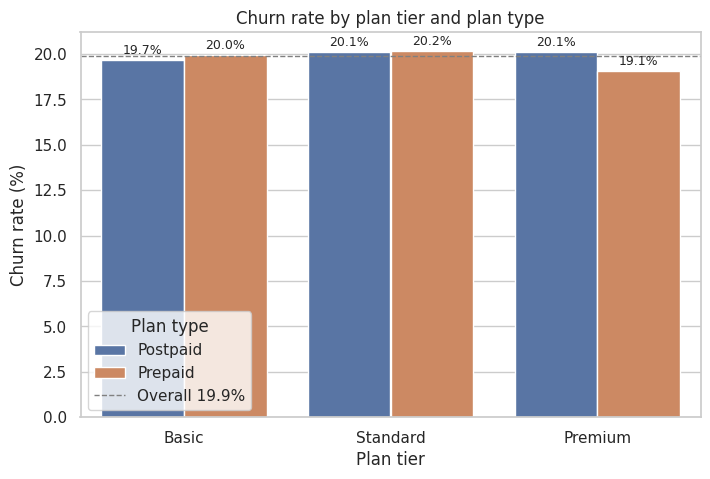

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
t = master.groupby(["plan_name", "plan_type"], observed=True)["is_churned"].mean().mul(100).reset_index()
sns.barplot(data=t, x="plan_name", y="is_churned", hue="plan_type", ax=ax)
ax.axhline(overall_churn * 100, color="grey", ls="--", lw=1, label=f"Overall {overall_churn:.1%}")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", padding=2, fontsize=9)
ax.set(title="Churn rate by plan tier and plan type", xlabel="Plan tier", ylabel="Churn rate (%)")
ax.legend(title="Plan type")
save(fig, "01_churn_by_plan.png")

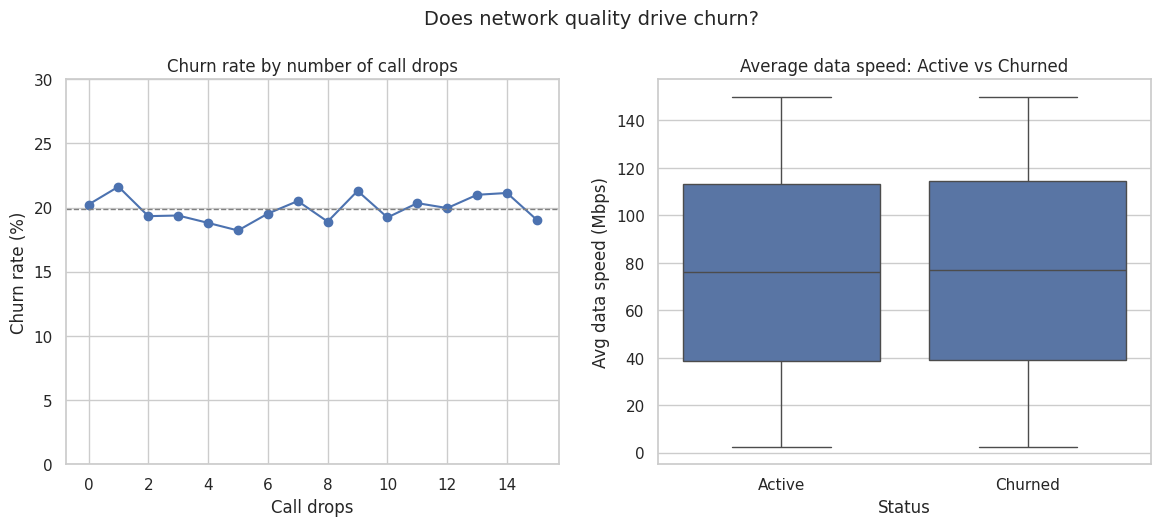

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cd = master.groupby("call_drops")["is_churned"].agg(["mean", "size"]).reset_index()
axes[0].plot(cd["call_drops"], cd["mean"] * 100, marker="o")
axes[0].axhline(overall_churn * 100, color="grey", ls="--", lw=1)
axes[0].set(title="Churn rate by number of call drops", xlabel="Call drops", ylabel="Churn rate (%)", ylim=(0, 30))

sns.boxplot(data=master, x="status", y="avg_data_speed_mbps", ax=axes[1])
axes[1].set(title="Average data speed: Active vs Churned", xlabel="Status", ylabel="Avg data speed (Mbps)")

fig.suptitle("Does network quality drive churn?", y=1.02, fontsize=14)
save(fig, "02_network_vs_churn.png")

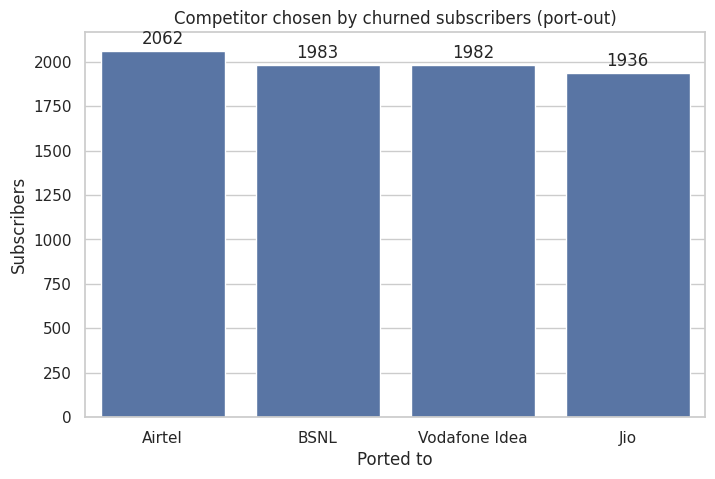

In [13]:
ported = master.loc[master.is_churned == 1, "ported_to"].astype(str).value_counts()
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=ported.index, y=ported.values, ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%d", padding=2)
ax.set(title="Competitor chosen by churned subscribers (port-out)", xlabel="Ported to", ylabel="Subscribers")
save(fig, "03_ported_to.png")

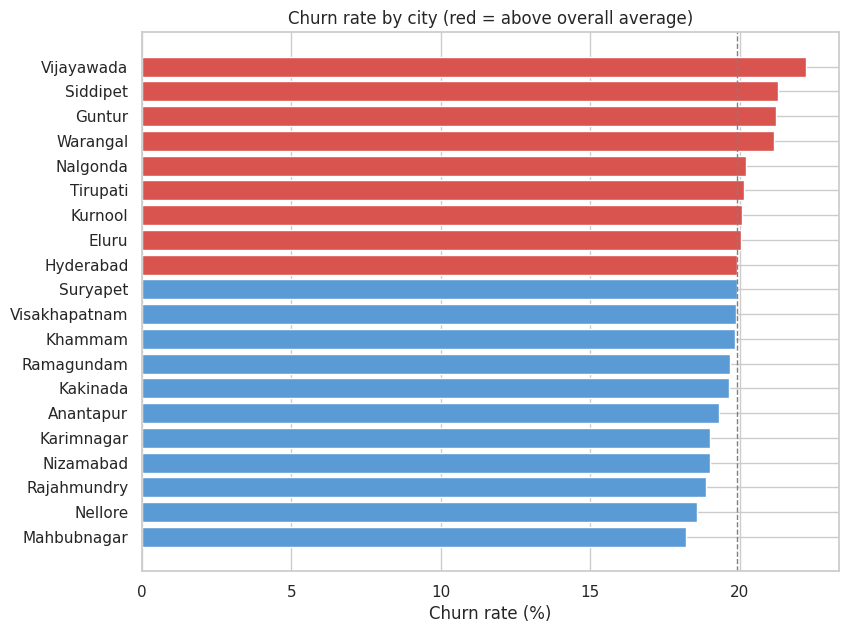

In [14]:
city = (master.groupby("city", observed=True)["is_churned"].agg(["mean", "size"])
              .rename(columns={"mean": "churn_rate"}).sort_values("churn_rate"))
fig, ax = plt.subplots(figsize=(9, 7))
colors = ["#d9534f" if v > overall_churn else "#5b9bd5" for v in city["churn_rate"]]
ax.barh(city.index.astype(str), city["churn_rate"] * 100, color=colors)
ax.axvline(overall_churn * 100, color="grey", ls="--", lw=1)
ax.set(title="Churn rate by city (red = above overall average)", xlabel="Churn rate (%)", ylabel="")
save(fig, "04_churn_by_city.png")

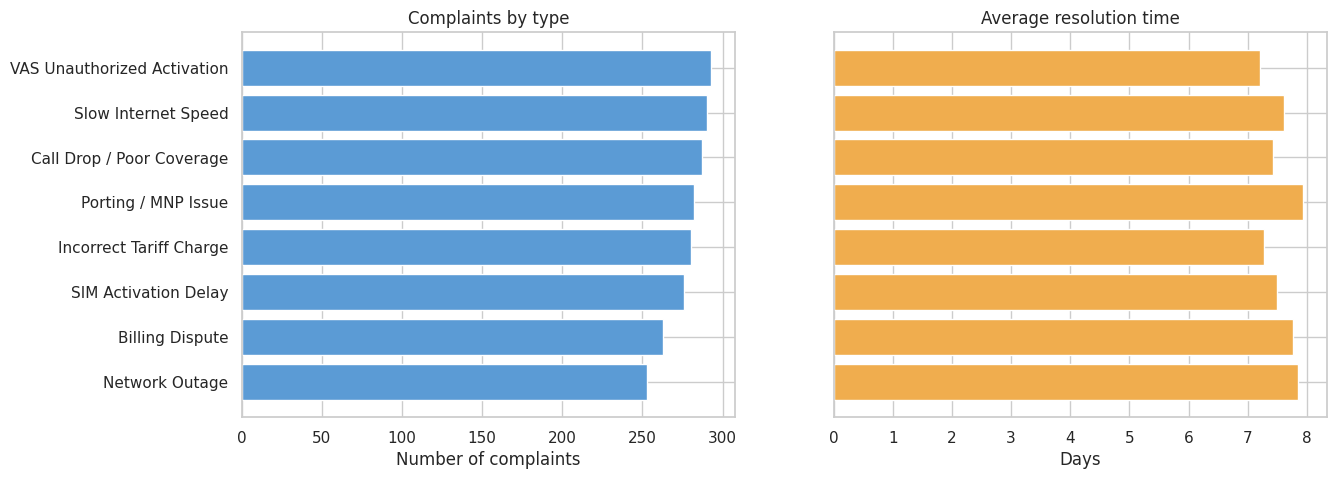

In [15]:
ct = (complaints.groupby("complaint_type", observed=True)
                .agg(count=("complaint_id", "size"), avg_resolution_days=("resolution_days", "mean"))
                .sort_values("count"))
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
axes[0].barh(ct.index.astype(str), ct["count"], color="#5b9bd5")
axes[0].set(title="Complaints by type", xlabel="Number of complaints")
axes[1].barh(ct.index.astype(str), ct["avg_resolution_days"], color="#f0ad4e")
axes[1].set(title="Average resolution time", xlabel="Days")
save(fig, "05_complaints.png")

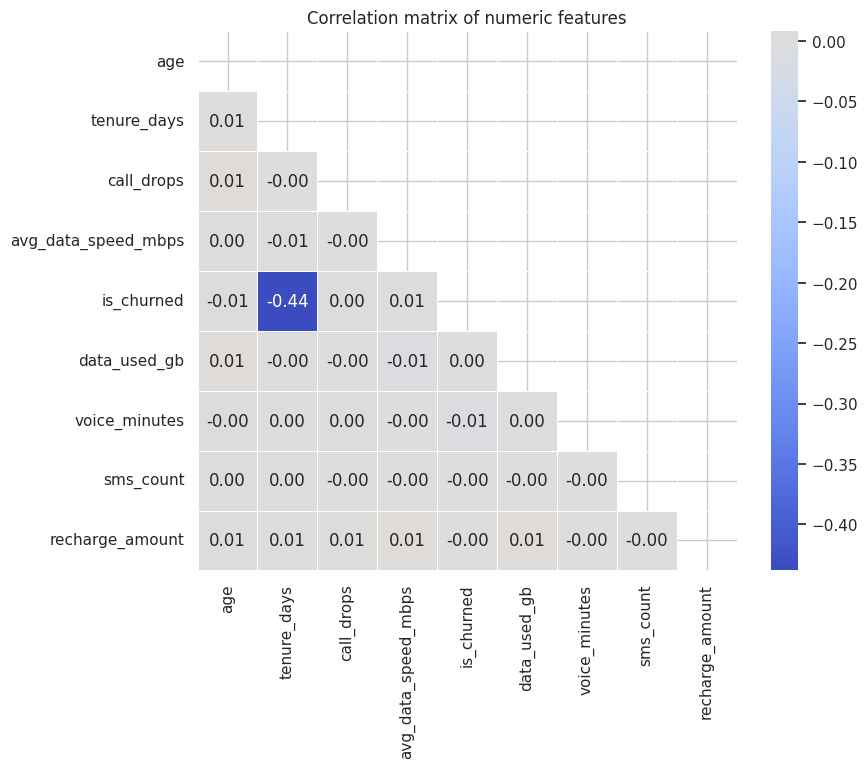

In [16]:
num_cols = ["age", "tenure_days", "call_drops", "avg_data_speed_mbps", "is_churned"]
if "data_used_gb" in master.columns:
    num_cols += ["data_used_gb", "voice_minutes", "sms_count", "recharge_amount"]
corr = master[num_cols].astype("float64").corr()

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=.5, ax=ax)
ax.set_title("Correlation matrix of numeric features")
save(fig, "06_correlation_heatmap.png")

In [17]:
exports = {
    "subscriber_clean.csv": subscriber,
    "network_clean.csv":    network,
    "status_clean.csv":     status,
    "usage_clean.csv":      usage,
    "complaints_clean.csv": complaints,
    "master_subscribers_clean.csv": master,
}
for fn, df in exports.items():
    df.to_csv(os.path.join(OUT_DIR, fn), index=False, date_format="%Y-%m-%d")
    print(f"saved {fn:32s} {df.shape}")

pd.DataFrame(audit).to_csv(os.path.join(OUT_DIR, "cleaning_audit_log.csv"), index=False)
print("saved cleaning_audit_log.csv")
print("figures ->", FIG_DIR)

saved subscriber_clean.csv             (40000, 7)
saved network_clean.csv                (40000, 4)
saved status_clean.csv                 (40000, 5)
saved usage_clean.csv                  (40000, 6)
saved complaints_clean.csv             (2224, 4)
saved master_subscribers_clean.csv     (40000, 20)
saved cleaning_audit_log.csv
figures -> /content/Cleaned_data/figures
